# Turing Patterns

In *The Chemical Basis of Morphogenesis* (1952), Alan Turing explored the mathematical foundations of the development of living organisms. In particular, he focused on the curious patterns that appear in living organisms. Turing discovered that "dappled" patterns could be produced by choosing a random set of numbers $U \in \{-1, 1\}^{r \times s}$, and applying the following equation:
$$ f(x, y) = \sum{U_{r,s}} \exp \bigg(-\frac{1}{2}\big((x - hr)^2 + (y - hs)^2\big)\bigg)$$
using a value of $h = 0.7$ and an approximation of the exponential function (remember, Turing was working before calculators capable of calculating exponential functions were widely available!)

Let's define this function in NumPy:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)  # fixed seed so the figures are reproducible

def turingLoop(h=0.7, maxVal=10, res=1000):
    # Generate randomized matrix
    U = np.sign(np.random.randn(2*maxVal, 2*maxVal))
    
    # Generate coordinate grid
    x = np.linspace(0, maxVal, res)
    X, Y = np.meshgrid(x, x)
    X = X.reshape((1, *X.shape))
    Y = Y.reshape((1, *Y.shape))
    Z = np.vstack((X,Y))

    def f(U, x, y):
        r, s = U.shape
        rs, ss = np.mgrid[0:r,0:s] # for indexing into U
        return np.sum(U * np.exp(-(1/2)*(((x - h*rs)**2) + ((y - h*ss)**2))))
    
    # Apply function f over coordinate grid
    Z = np.apply_along_axis(lambda x : f(U, *x), 0, Z)

    # Quantize values to {0, 1}
    return (np.sign(Z)+1)/2

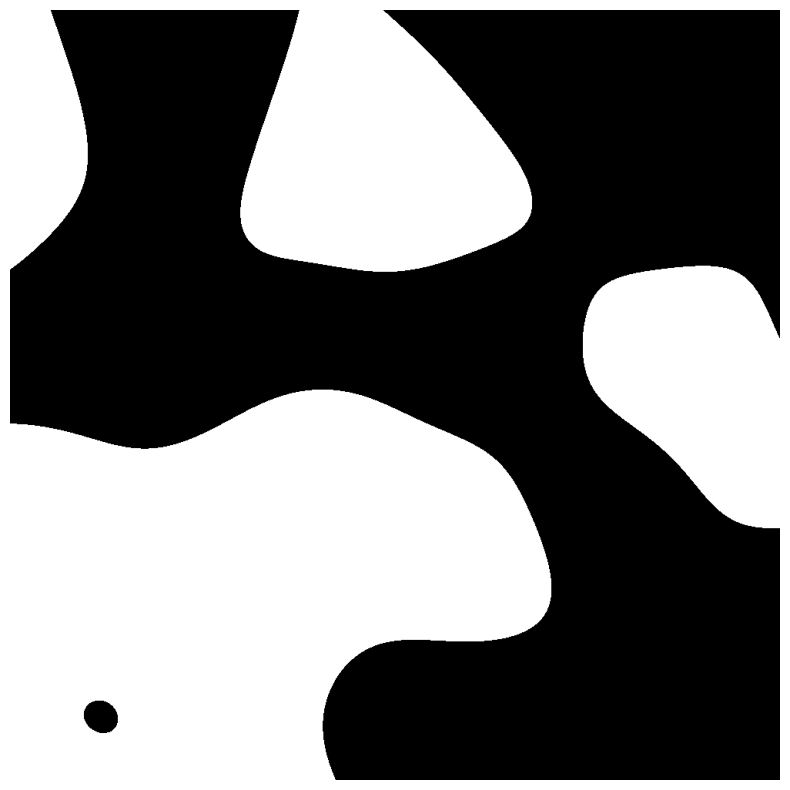

In [2]:
Z = turingLoop()
plt.figure(figsize=(10,10))
plt.axis('off')
plt.imshow(Z, cmap="gray")
plt.show()

In [3]:
def turingVectorized(h=0.7, maxVal=10, res=1000):
    U = np.sign(np.random.randn(2*maxVal, 2*maxVal))
    x = np.linspace(0, maxVal, res)
    X, Y = np.meshgrid(x, x)

    UTile = np.tile(U, (*X.shape, 1,1))
    UTile = np.moveaxis(UTile, [0,1,2,3], [2,3,0,1])
    XTile = np.tile(X, (*U.shape, 1, 1))
    YTile = np.tile(Y, (*U.shape, 1, 1))

    R, S = np.mgrid[:U.shape[0],:U.shape[1]]
    RTile = np.tile(R, (*X.shape, 1, 1))
    RTile = np.moveaxis(RTile, [0,1,2,3], [2,3,0,1])
    STile = np.tile(S, (*X.shape, 1, 1))
    STile = np.moveaxis(STile, [0,1,2,3], [2,3,0,1])

    Z = UTile * np.exp(-1/2 * ((XTile - h*RTile)**2 + (YTile - h*STile)**2))
    Z = np.sum(Z, axis=(0,1))
    return (np.sign(Z)+1)/2

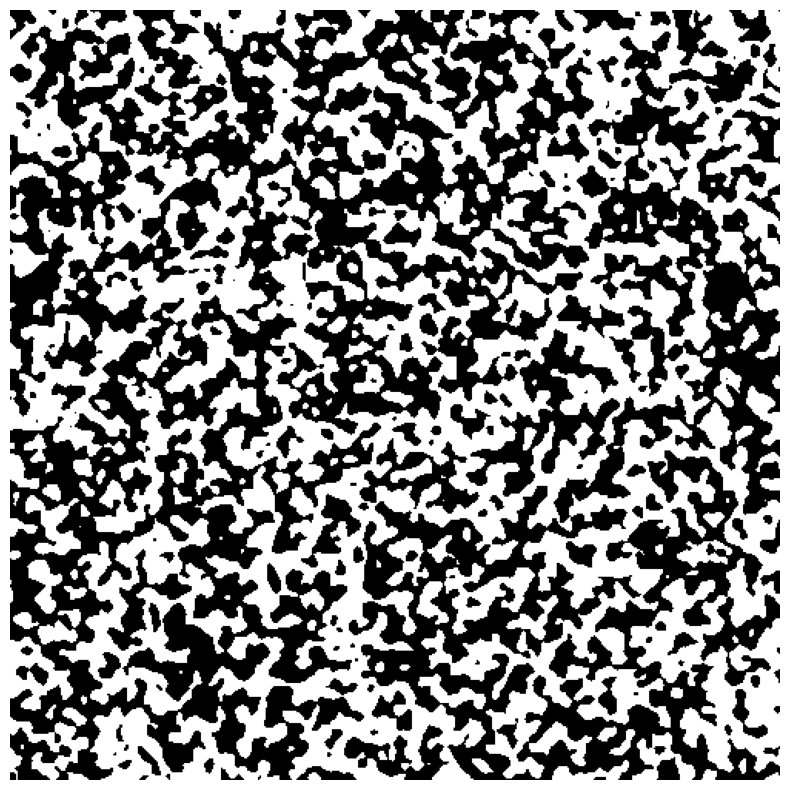

In [4]:
Z2 = turingLoop(maxVal=200, res=500)
plt.figure(figsize=(10,10))
plt.axis('off')
plt.imshow(Z2, cmap="gray")
plt.show()

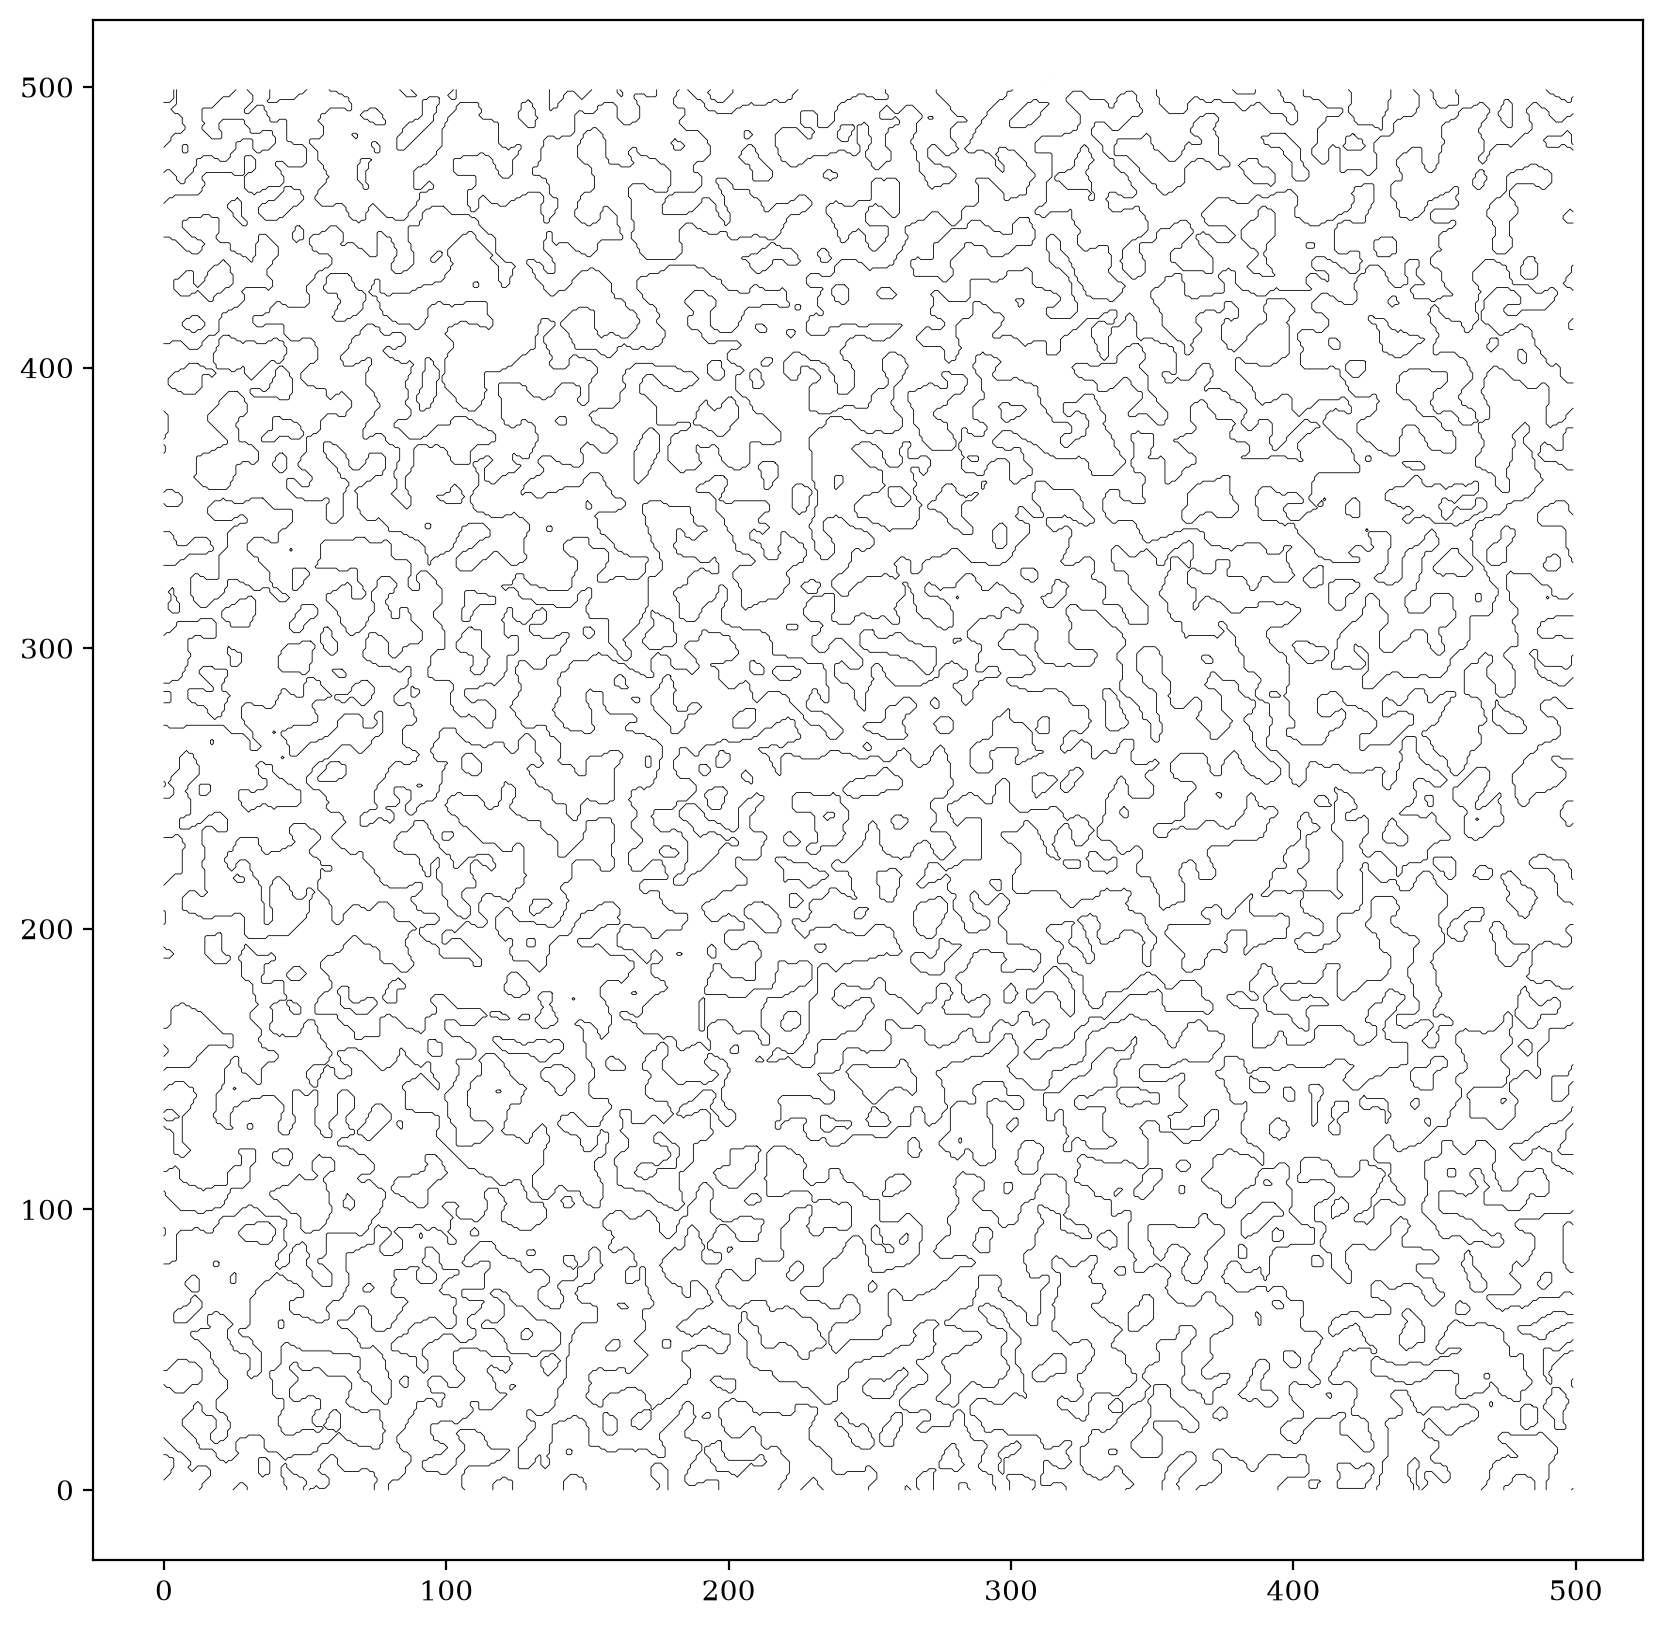

In [5]:
# %matplotlib notebook
%config InlineBackend.figure_format = 'retina'  # 2026 note: was 'svg'; PNG keeps the notebook small
plt.rcParams.update({
    "font.family": "serif"
})

from skimage.measure import find_contours
C = find_contours(Z2, 0.5)

plt.figure(figsize=(10,10))
for contour in C:
    plt.plot(contour[:, 1], contour[:, 0], c="k",linewidth=0.3)
plt.show()

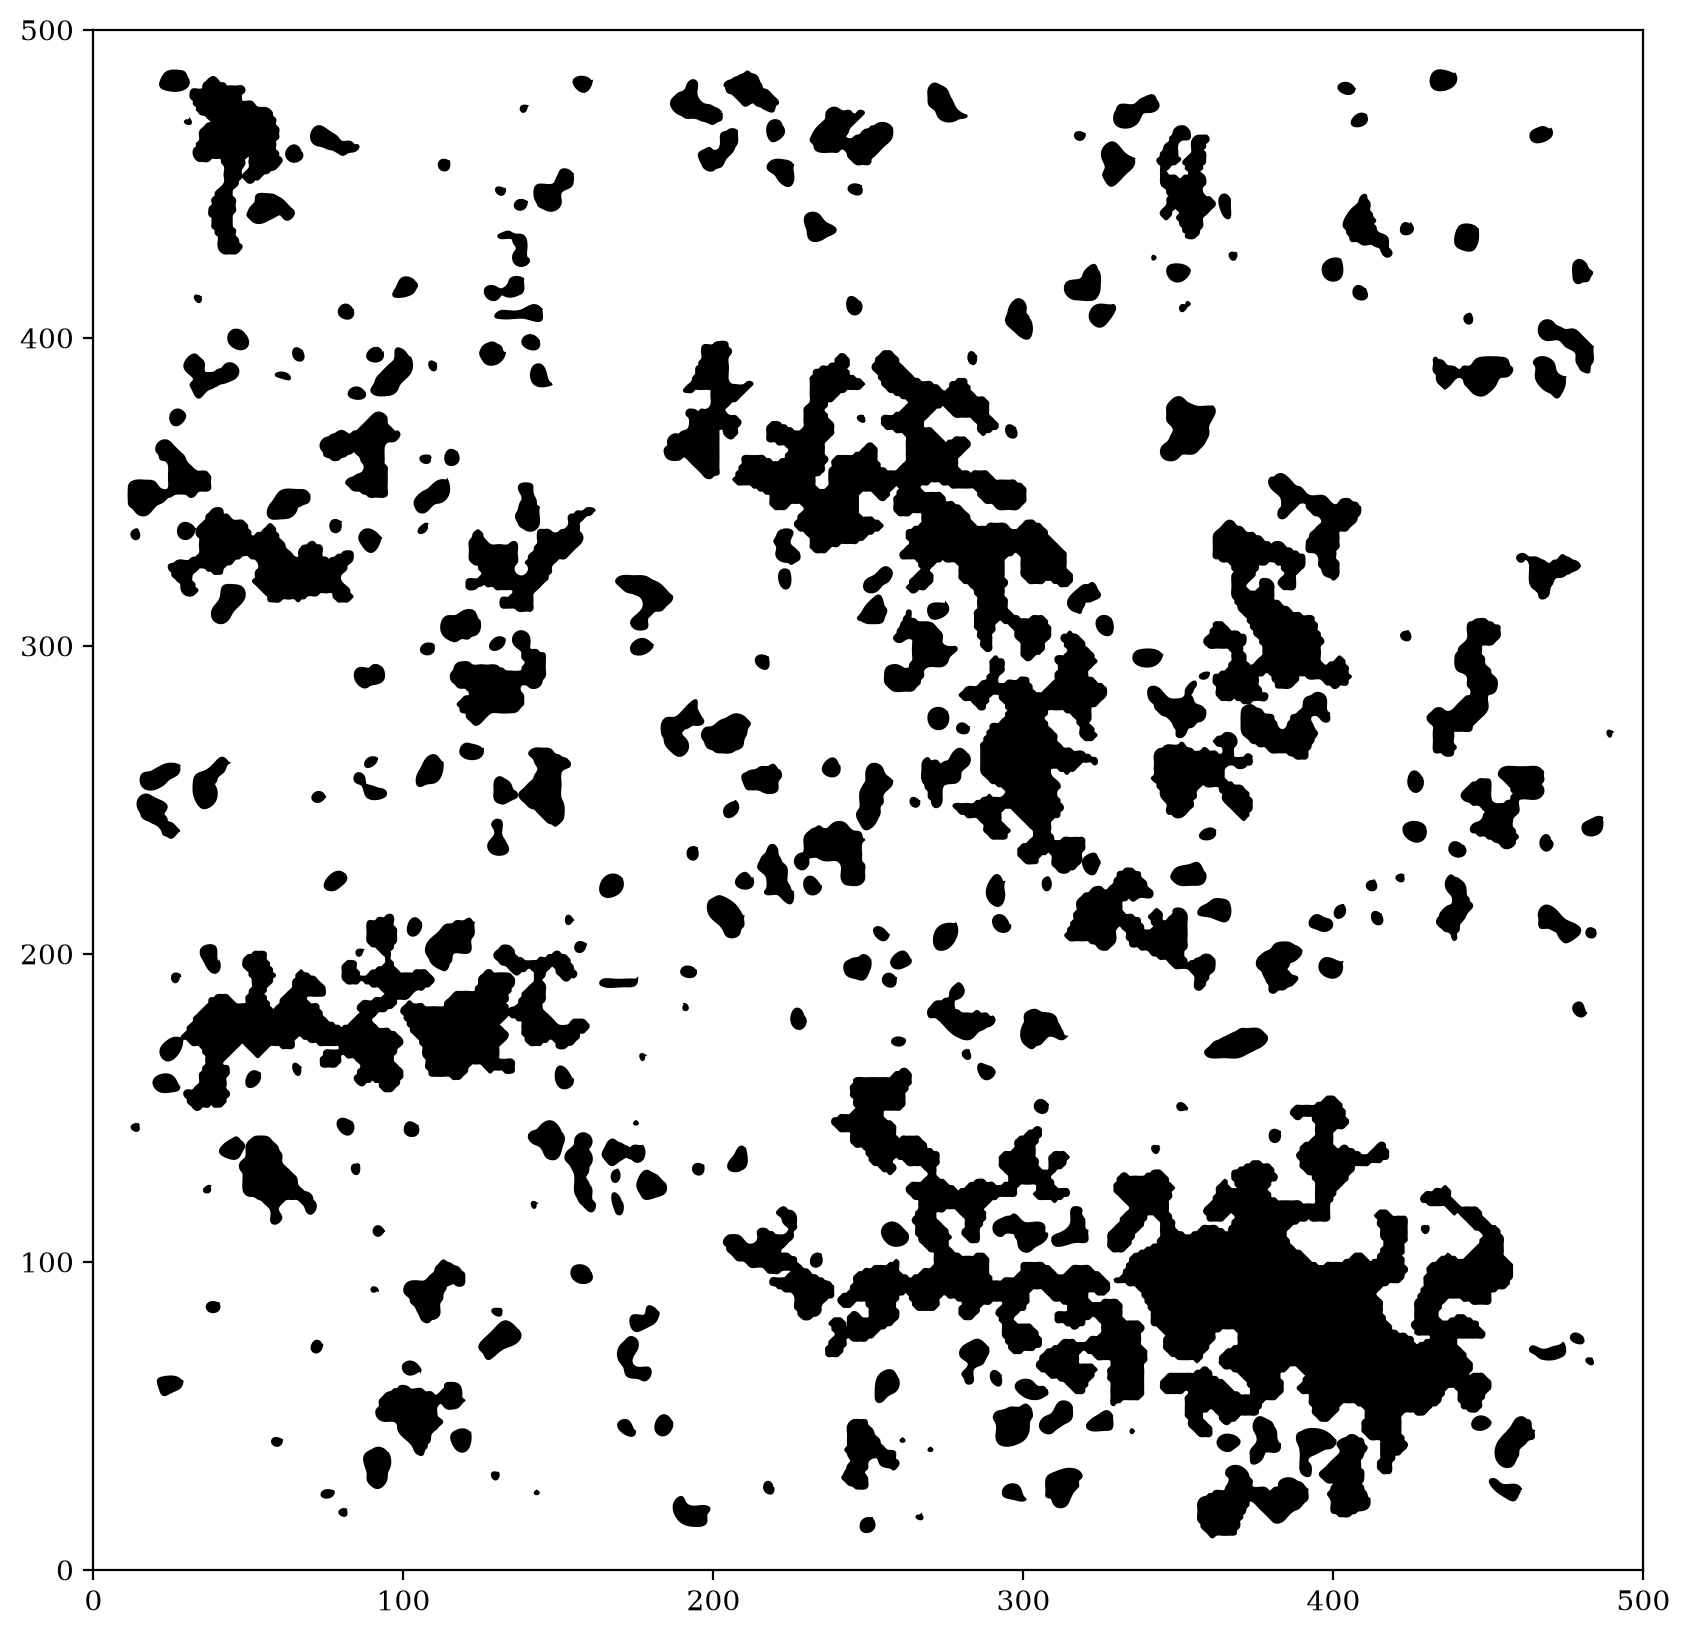

In [6]:
from scipy.interpolate import splev, splprep

plt.figure(figsize=(10,10))

out = []
for c in C:
    uniq, index = np.unique(c, axis=0, return_index=True)
    u = uniq[index.argsort()]
    u = np.vstack((u, u[0]))
    if u.shape[0] < 4:
        continue
    if np.max(u) > 490 or np.min(u) < 10:
        continue
    x, y = u[:,0], u[:,1]
    #plt.scatter(x, y, s=0.4)
    tck, u = splprep([x, y], s=1)
    unew = np.arange(0, 1, 0.0005)
    out.append(splev(unew, tck))
    
for contour in out:
    plt.fill(*contour, c='black')
plt.xlim(0,500)
plt.ylim(0,500)
plt.show()

In [7]:
from numba import jit

@jit
def turingCore(U, x, y, z, h, rs, ss, ts):
    return np.sum(U * np.exp(-(1/2)*(((x - h*rs)**2) + ((y - h*ss)**2) + ((z - h*ts)**2))))


@jit(nopython=True)
def turingNumba(U, X, Y, Z, h, rs, ss, ts):
    R = np.zeros_like(X)
    for i in range(Z.shape[0]):
        for j in range(Z.shape[0]):
            for k in range(Z.shape[0]):
                x = X[i][j][k]
                y = Y[i][j][k]
                z = Z[i][j][k]
                R[i][j][k] = turingCore(U, x, y, z, h, rs, ss, ts) 
    return R

def turing3(h=0.3, maxVal=30, res=60):
    # Generate randomized matrix
    U = np.sign(np.random.randn(4*maxVal, 4*maxVal, 4*maxVal))
    r, s, t = U.shape
    rs, ss, ts = np.mgrid[0:r,0:s,0:t] # for indexing into U
    # Generate coordinate grid
    x = np.linspace(0, maxVal, res)
    X, Y, Z = np.meshgrid(x, x, x)
    return turingNumba(U, X, Y, Z, h, rs, ss, ts)

# 2026 note: these calls now run through turing3Separable (two cells down),
# which gives the same arrays; see the note below.
# Z6 = turing3()
# Z4's parameters are a reconstruction: the originals were lost in 2022;
# these match the blog figure's contour count.
# Z4 = turing3(h=0.3, maxVal=10, res=50)

### 2026 note: separable evaluation

The Gaussian in the 3D sum factors per axis:
$$\exp\Big(-\tfrac{1}{2}\big((x - hr)^2 + (y - hs)^2 + (z - ht)^2\big)\Big) = g(x - hr)\,g(y - hs)\,g(z - ht), \qquad g(u) = e^{-u^2/2}.$$
So if $G_{ir} = g(x_i - hr)$ is the matrix of Gaussians between grid points and lattice points, the whole lattice sum on the grid is three matrix products, one per axis. This is the standard separable-filter fact, not a new result. `turing3Separable` below computes it this way. It draws `U` exactly as `turing3` does and returns the same array up to floating-point rounding; the cell below checks this against the numba path on small grids.

`turingCore`, `turingNumba` and `turing3` above are unchanged; they are the code the blog post describes. The calls that produce `Z4`, `Z6` and `Z7` now go through `turing3Separable`, with the original calls kept as comments. The reason is time. On current hardware (an Apple M5 Max in 2026) the numba path costs about 30 ms per grid point for `Z7`'s $200 \times 200 \times 200$ lattice, so the committed `Z7` ($100^3$ grid points) would take about 8 hours, and `Z6` about half an hour. The separable form takes well under a second for either.

The post says the larger patterns took "under an hour". At the committed parameters this code takes about 8 hours on current hardware, so that run probably used a smaller `res` than the committed 100, or other parameters. This is an inference: the 2022 run isn't recorded, and the contour count in the post's figure doesn't pin `res` down, because it changes about as much between random draws of `U` as between nearby values of `res`.

In [8]:
# 2026 note: separable evaluation of turing3's lattice sum
def gaussMatrix(x, n, h):
    # G[i, r] = exp(-(1/2)(x_i - h r)^2)
    r = np.arange(n)
    return np.exp(-(1/2)*(x[:, None] - h*r[None, :])**2)

def turing3Separable(h=0.3, maxVal=30, res=60):
    # Same random matrix and grid as turing3
    U = np.sign(np.random.randn(4*maxVal, 4*maxVal, 4*maxVal))
    x = np.linspace(0, maxVal, res)
    G = gaussMatrix(x, U.shape[0], h)  # U is a cube, so one matrix serves all three axes
    # np.meshgrid(x, x, x) gives X[i,j,k] = x[j], Y[i,j,k] = x[i], Z[i,j,k] = x[k],
    # and turing3 pairs X with rs (axis 0 of U), Y with ss (axis 1), Z with ts (axis 2).
    A = np.tensordot(G, U, axes=(1, 0))  # sum over r -> A[j, s, t]
    A = np.tensordot(G, A, axes=(1, 1))  # sum over s -> A[i, j, t]
    A = np.tensordot(A, G, axes=(2, 1))  # sum over t -> A[i, j, k]
    return A

# Check against turing3's numba path on small grids, with the same U for both.
# The RNG state is restored afterwards, so the check doesn't shift the random draws the figures use.
state = np.random.get_state()
for h, maxVal, res in [(0.3, 5, 16), (0.7, 5, 16)]:
    np.random.set_state(state)
    small = turing3(h=h, maxVal=maxVal, res=res)
    np.random.set_state(state)
    smallSep = turing3Separable(h=h, maxVal=maxVal, res=res)
    print(f"h={h}, maxVal={maxVal}, res={res}: allclose {np.allclose(small, smallSep)}, "
          f"identical signs {np.array_equal(np.sign(small), np.sign(smallSep))}, "
          f"max abs difference {np.abs(small - smallSep).max():.1e}")
    assert np.allclose(small, smallSep) and np.array_equal(np.sign(small), np.sign(smallSep))
np.random.set_state(state)

Z6 = turing3Separable()                          # Z6 = turing3()
Z4 = turing3Separable(h=0.3, maxVal=10, res=50)  # Z4 = turing3(h=0.3, maxVal=10, res=50)

h=0.3, maxVal=5, res=16: allclose True, identical signs True, max abs difference 2.6e-13
h=0.7, maxVal=5, res=16: allclose True, identical signs True, max abs difference 4.4e-14


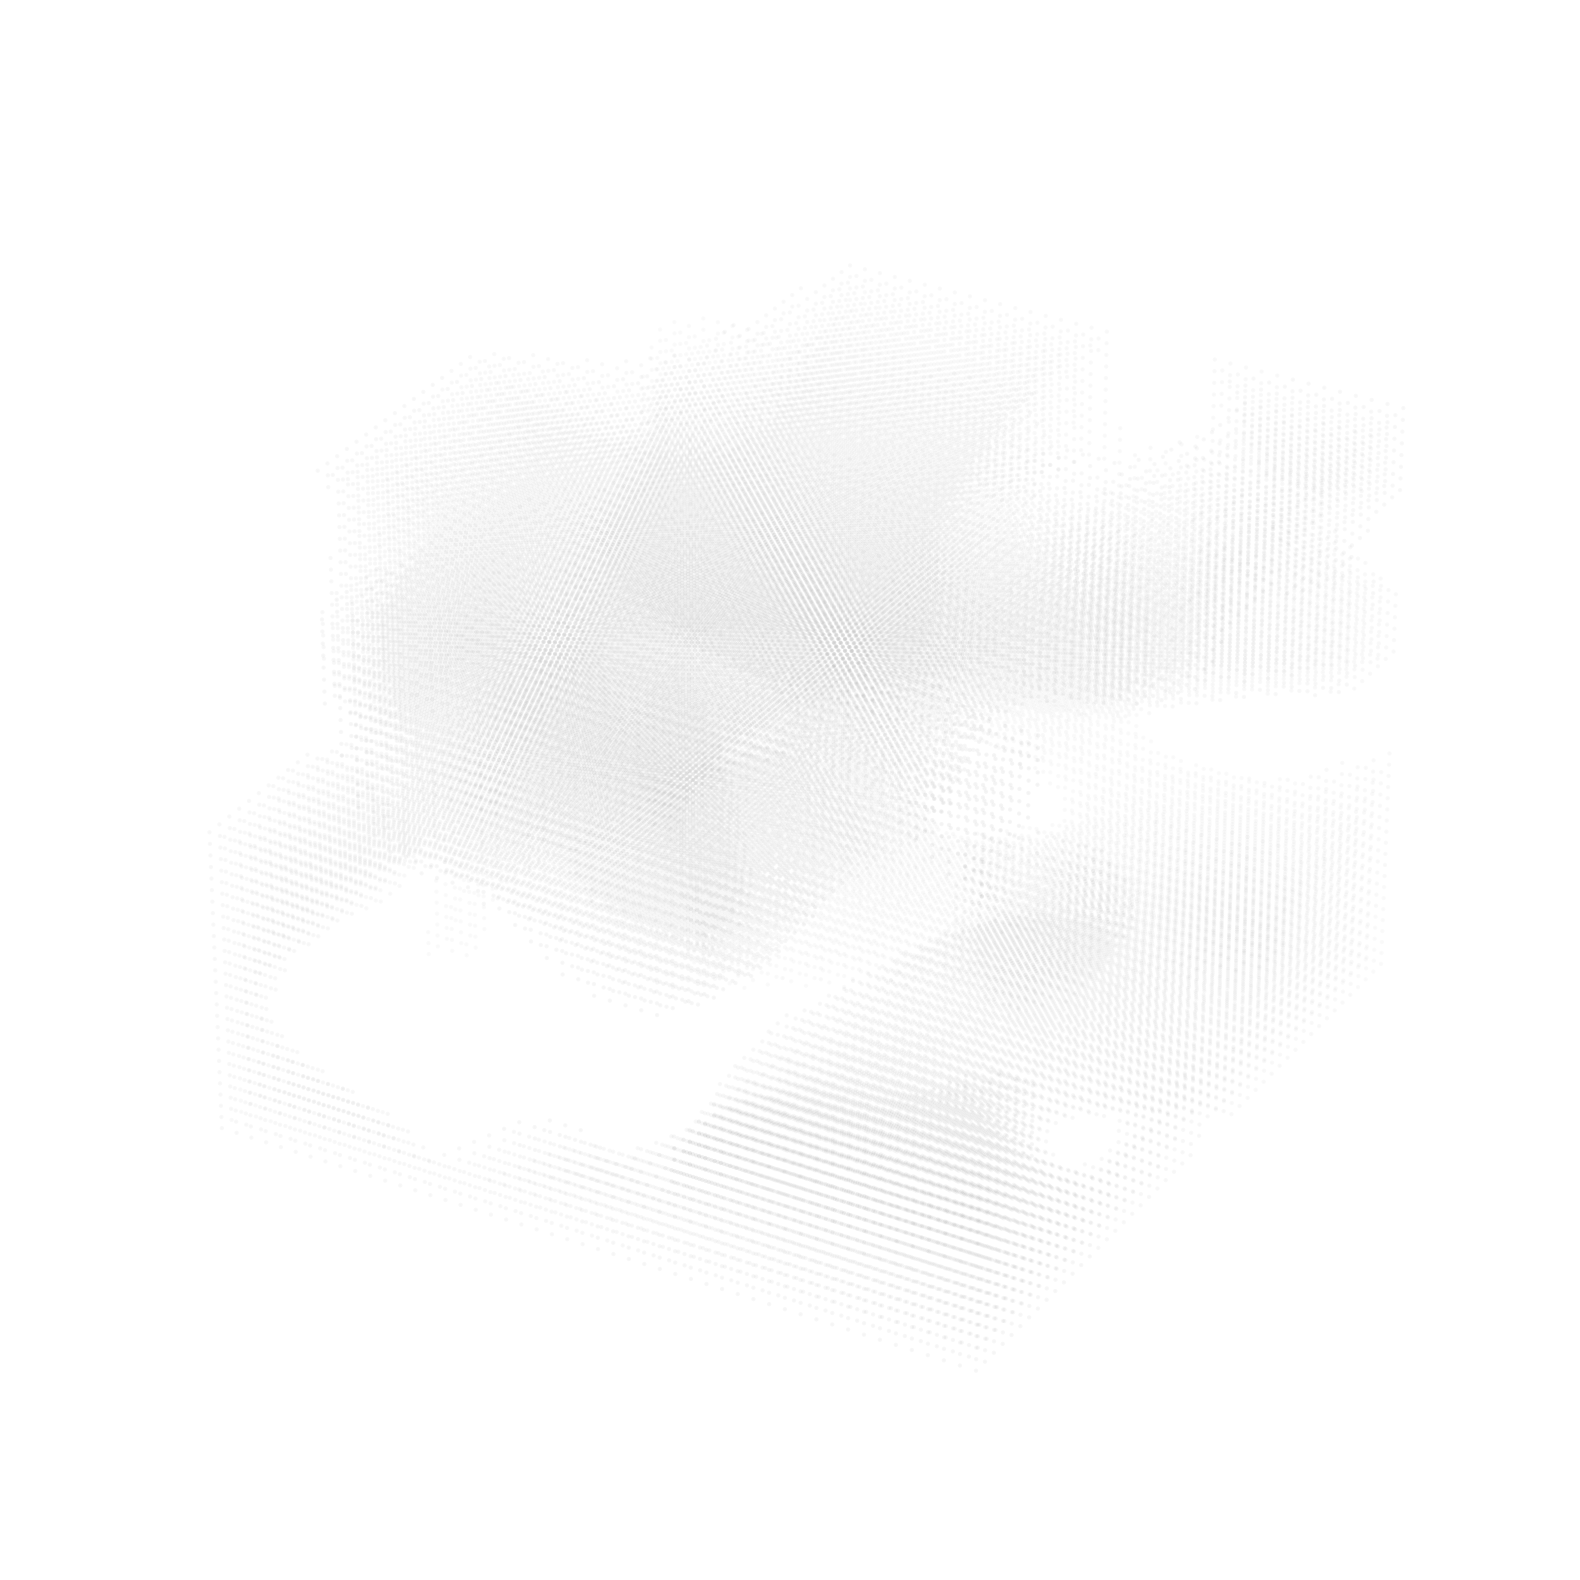

In [9]:
%matplotlib inline

fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection ='3d')
ax.scatter(*np.where(Z4>0),alpha=0.2, s=.3, c='black', rasterized=True)
plt.axis("off")
plt.savefig("turing3D_pointcloud.svg", dpi=300)  # 2026 note: scatter is rasterized, so pick a high DPI
plt.show()

In [10]:
# Z6 = turing3()
Z6 = turing3Separable()

In [11]:
# 2026 note: the original call takes about 8 hours with the numba path (see the note above).
# Z7 = turing3(h=0.7, maxVal=50, res=100)
Z7 = turing3Separable(h=0.7, maxVal=50, res=100)

In [12]:
np.save("Z73d", Z7)

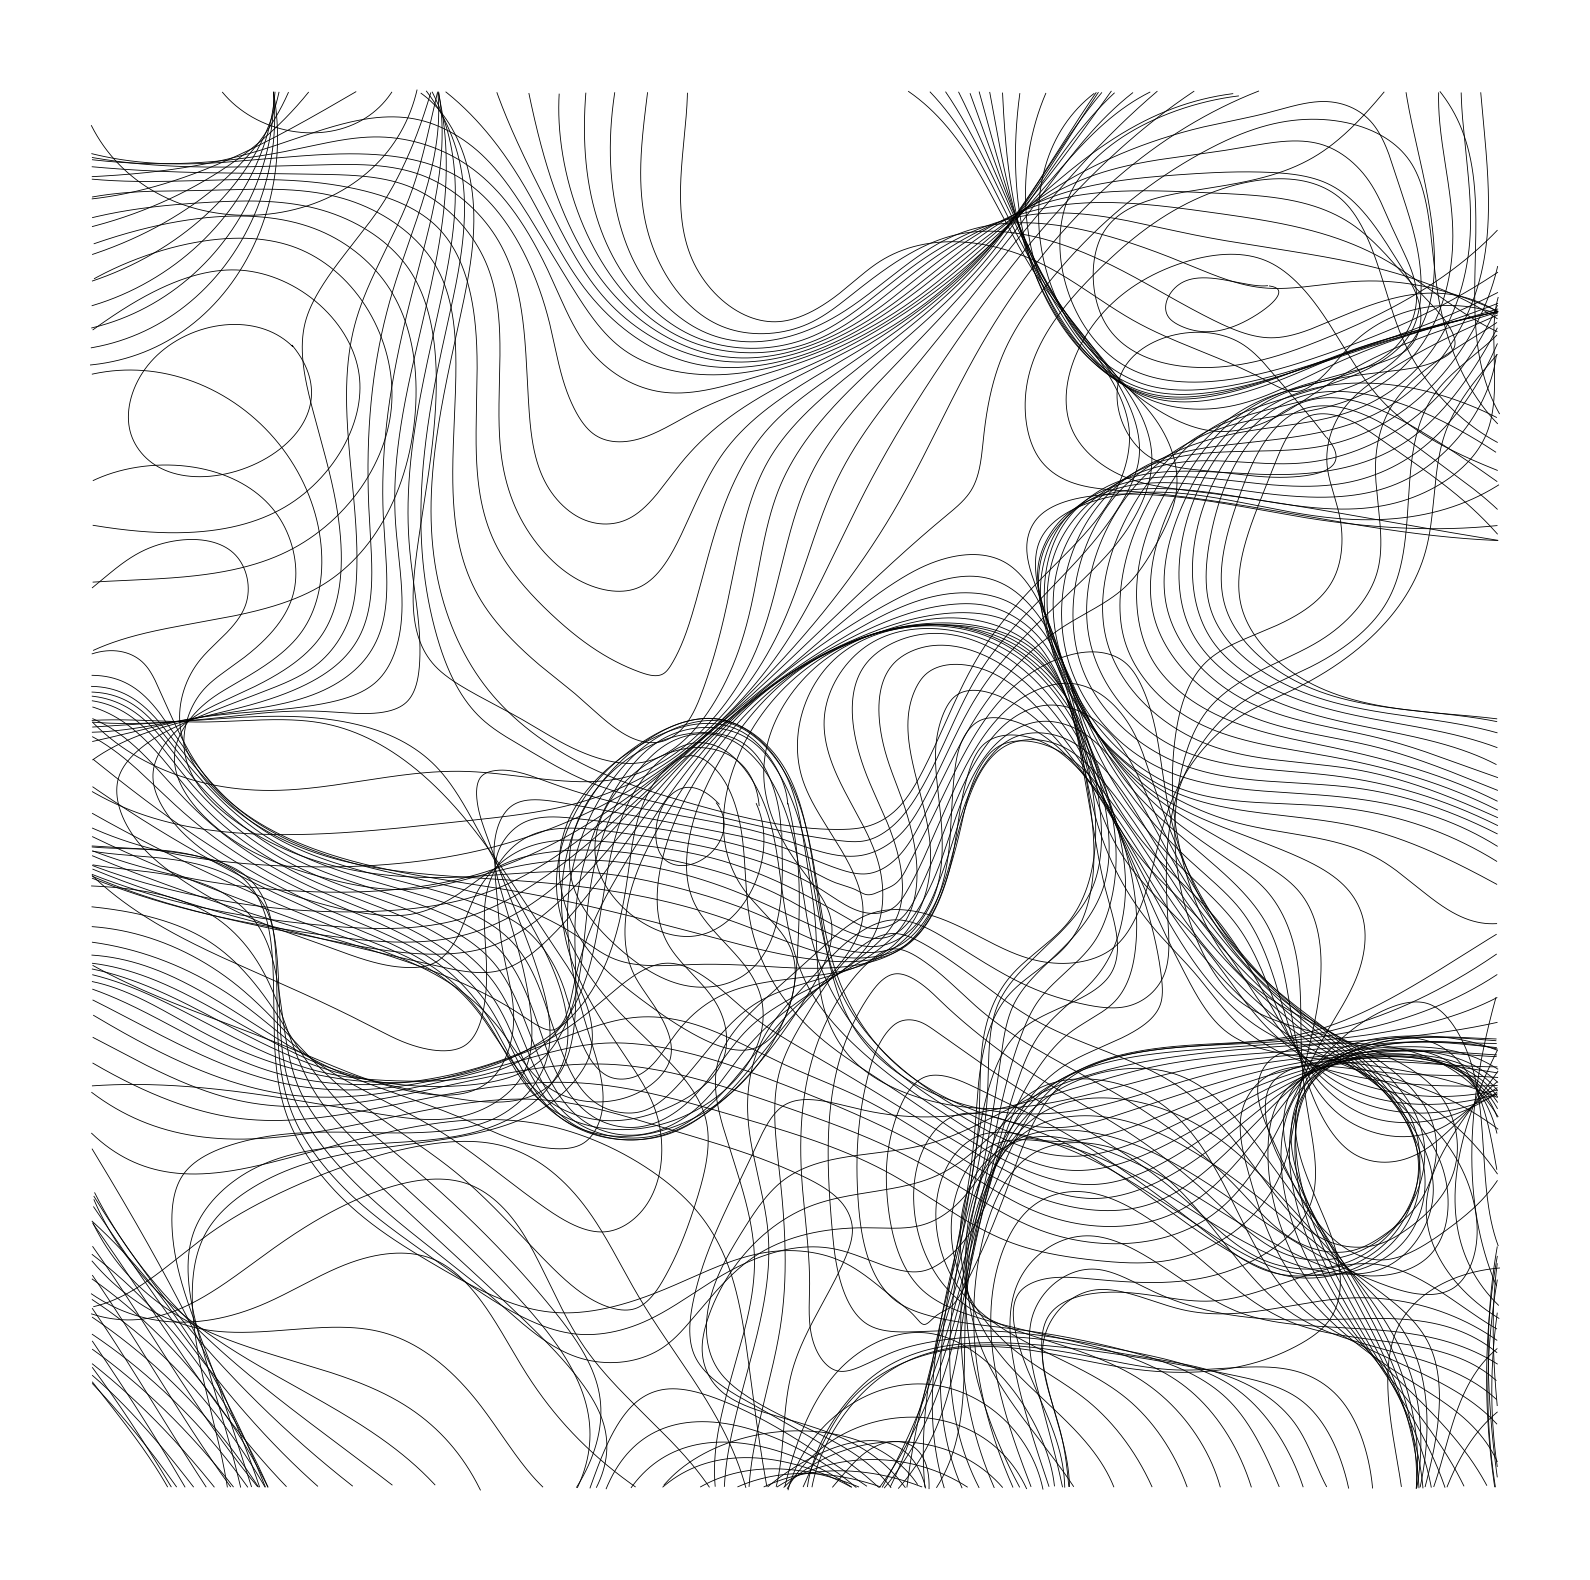

In [13]:
fig = plt.figure(figsize=(10,10))

for i, s in enumerate(Z4):
    cs = find_contours(s, 0.0)
    for c in cs:
        x, y = c[:,0], c[:,1]
        if len(x) < 5:
            continue
        tck, u = splprep([x, y], s=.1)
        unew = np.arange(0, 1, 0.00005)
        splines = splev(unew, tck)
        plt.plot(*splines, linewidth=0.3, c="black")
plt.axis('off')
plt.savefig("turing3D1.svg")
plt.show()

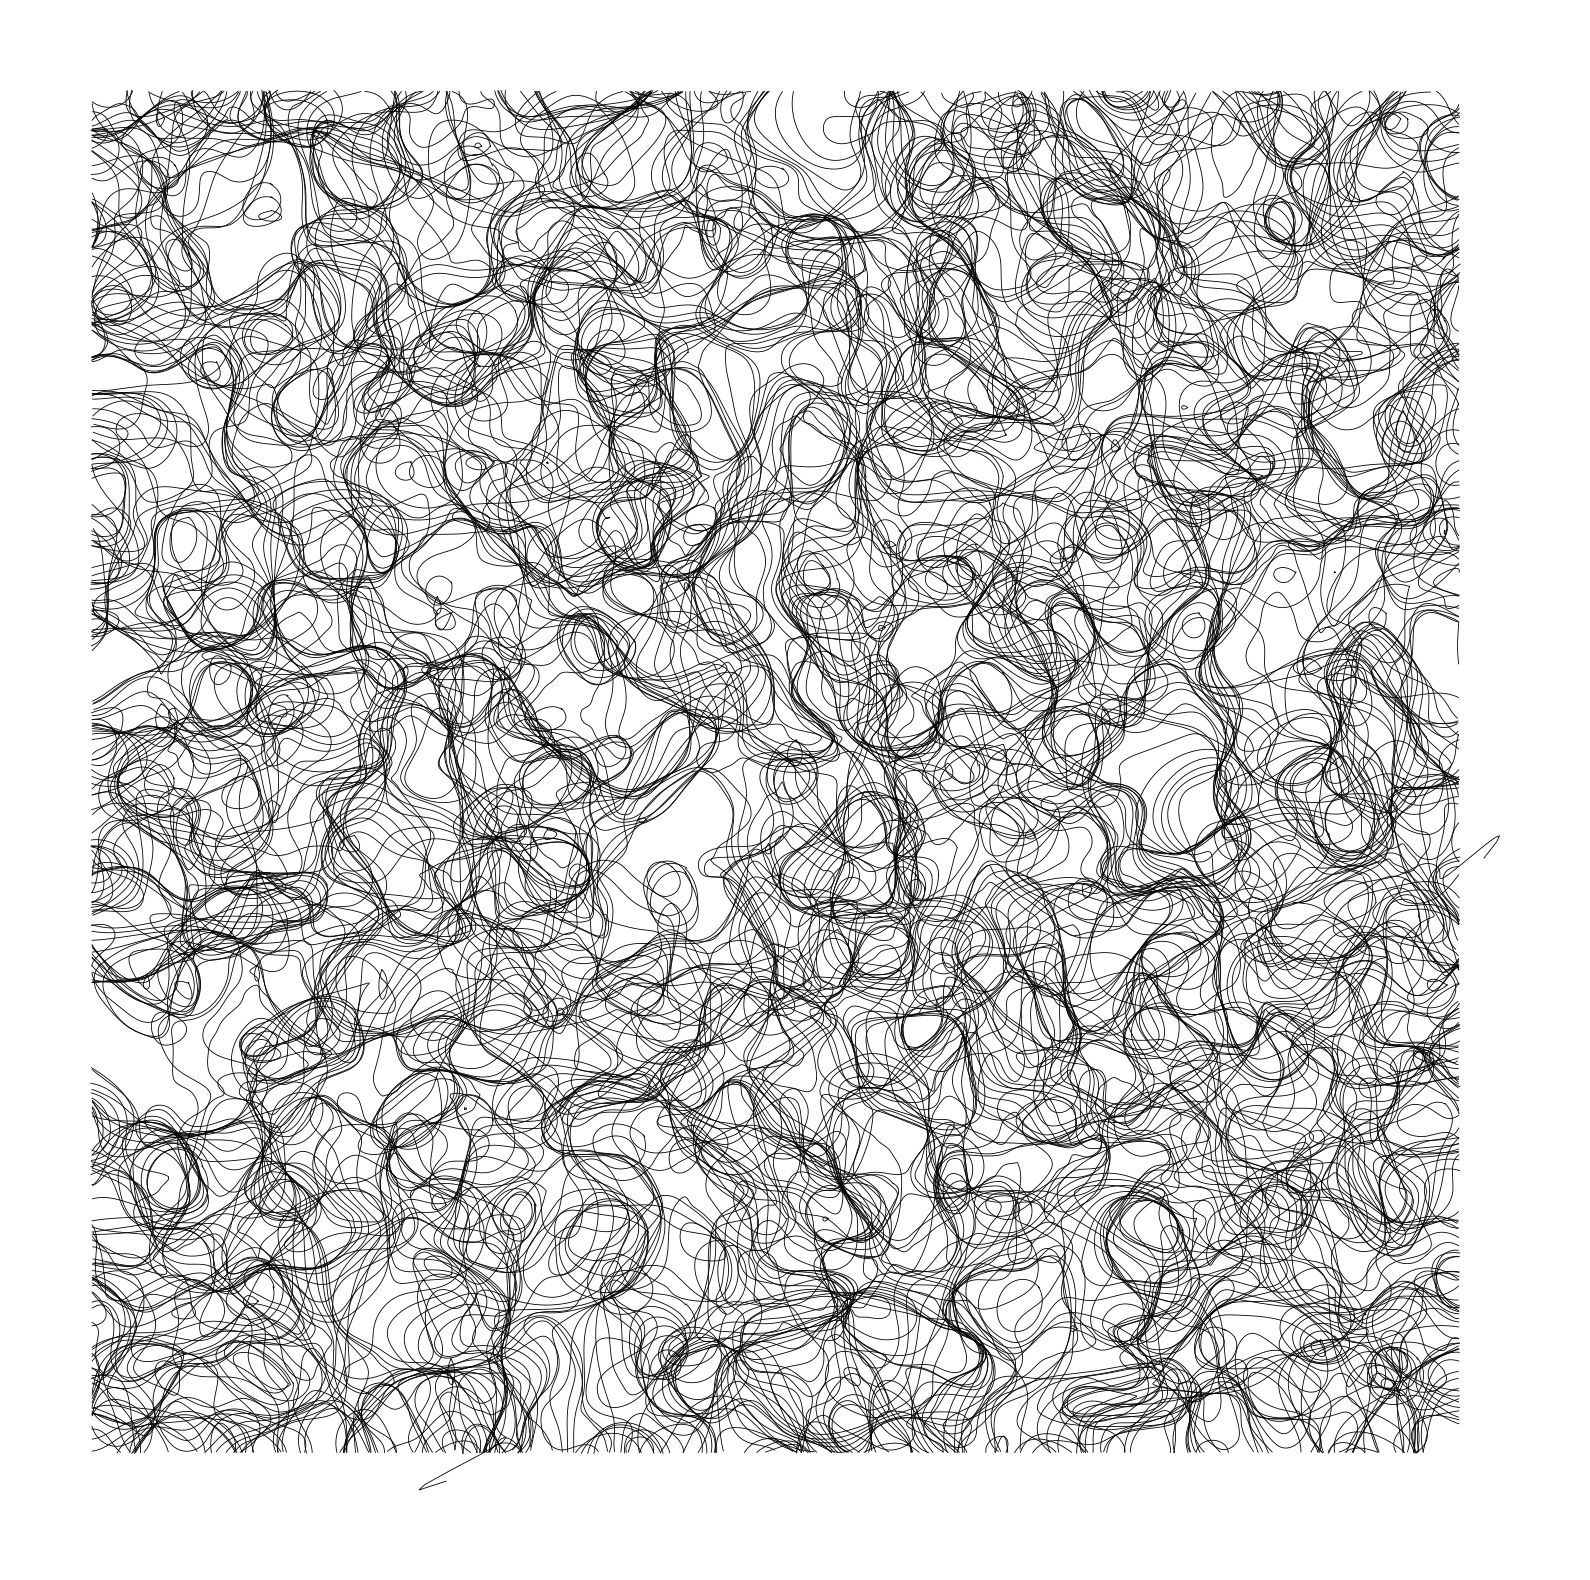

In [14]:
fig = plt.figure(figsize=(10,10))

Zslice = Z7[15:40,:,:]

for i, s in enumerate(Zslice):
    cs = find_contours(s, 0.0)
    for c in cs:
        x, y = c[:,0], c[:,1]
        if len(x) < 5:
            continue
        tck, u = splprep([x, y], s=.1)
        unew = np.arange(0, 1, 0.0005)
        splines = splev(unew, tck)
        plt.plot(*splines, linewidth=0.3, c="black")
plt.axis('off')
plt.savefig("turing3D2.svg")
plt.show()